In [1]:
import numpy as np
import pandas as pd

np.random.seed(23)

mu_vec1 = np.array([0, 0, 0])

cov_mat1 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class1_sample = np.random.multivariate_normal(
    mu_vec1, cov_mat1, 20
)

df = pd.DataFrame(
    class1_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df['target'] = 1

mu_vec2 = np.array([1, 1, 1])

cov_mat2 = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

class2_sample = np.random.multivariate_normal(
    mu_vec2, cov_mat2, 20
)

df1 = pd.DataFrame(
    class2_sample,
    columns=['feature1', 'feature2', 'feature3']
)

df1['target'] = 0

# Combine both DataFrames
df = pd.concat([df, df1], ignore_index=True)

# Shuffle the dataset
df = df.sample(40)

# Display the dataset
print(df)

# Check the shape
print(df.shape)

    feature1  feature2  feature3  target
2  -0.367548 -1.137460 -1.322148       1
34  0.177061 -0.598109  1.226512       0
14  0.420623  0.411620 -0.071324       1
11  1.968435 -0.547788 -0.679418       1
12 -2.506230  0.146960  0.606195       1
29  1.425140  1.441152  0.182561       0
31  2.224431  0.230401  1.192120       0
4   0.322272  0.060343 -1.043450       1
32 -0.723253  1.461259 -0.085367       0
33  2.823378 -0.332863  2.637391       0
36 -1.389866  0.666726  1.343517       0
18 -0.331617 -1.632386  0.619114       1
0   0.666988  0.025813 -0.777619       1
5  -1.009942  0.441736  1.128877       1
39  0.384865  1.323546 -0.103193       0
22  1.676860  4.187503 -0.080565       0
8   0.241106 -0.952510 -0.136267       1
15 -0.045438  1.040886 -0.094035       1
19 -0.992574 -0.161346  1.192404       1
30  1.437892  1.099723  1.065406       0
25  0.290746  0.866975  0.982643       0
21  0.731858  0.517441  2.244610       0
37 -1.027861  1.131416  2.603234       0
16 -0.420844 -0.

In [2]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='feature1',
    y='feature2',
    z='feature3',
    color=df['target'].astype(str)
)

fig.update_traces(
    marker=dict(
        size=12,
        line=dict(
            width=2,
            color='DarkSlateGrey'
        )
    ),
    selector=dict(mode='markers')
)

fig.show()

In [3]:

# Step 1 - Apply standard scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df.iloc[:,0:3] = scaler.fit_transform(df.iloc[:,0:3])

In [4]:

# Step 2 - Find Covariance Matrix
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[:,1],df.iloc[:,2]])
print('Covariance Matrix:\n', covariance_matrix)

Covariance Matrix:
 [[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [15]:
eigen_values, eigen_vectors = np.linalg.eigh(cov_mat)

In [23]:
idx = np.argsort(eigen_values)[::-1]

eigen_values = eigen_values[idx]
eigen_vectors = eigen_vectors[:, idx]

In [26]:
eigen_values = eigen_values.real
eigen_vectors = eigen_vectors.real

In [27]:

eigen_values

array([1.3536065 , 0.94557084, 0.77774573])

In [28]:

eigen_vectors

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442],
       [-0.52848211,  0.72025103,  0.44938304]])

c:\Users\LENOVO\Desktop\machine learning\.venv\Lib\site-packages\matplotlib\transforms.py:1913: ComplexWarning: Casting complex values to real discards the imaginary part
  return affine_transform(values, mtx)


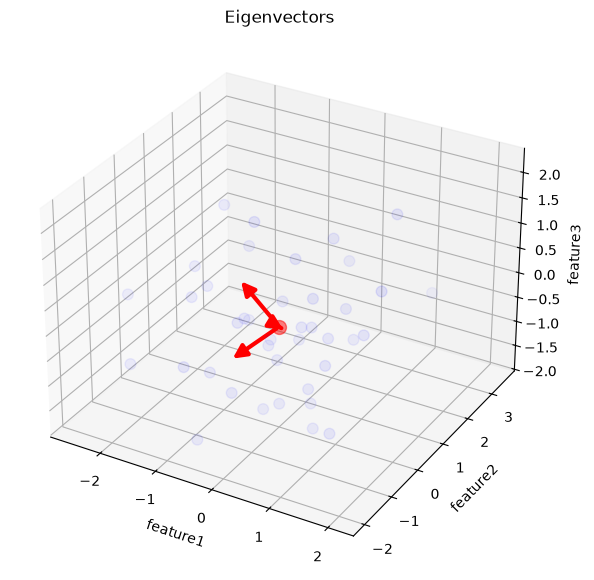

In [29]:
import numpy as np
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch


class Arrow3D(FancyArrowPatch):

    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def draw(self, renderer):
        xs3d, ys3d, zs3d = self._verts3d

        xs, ys, zs = proj3d.proj_transform(
            xs3d, ys3d, zs3d, self.axes.get_proj()
        )

        self.set_positions(
            (xs[0], ys[0]),
            (xs[1], ys[1])
        )

        super().draw(renderer)

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d

        xs, ys, zs = proj3d.proj_transform(
            xs3d, ys3d, zs3d, self.axes.get_proj()
        )

        self.set_positions(
            (xs[0], ys[0]),
            (xs[1], ys[1])
        )

        return np.min(zs)


# Calculate the mean of each feature
mean = df[['feature1', 'feature2', 'feature3']].mean().values

# Calculate covariance matrix
cov_mat = np.cov(
    df[['feature1', 'feature2', 'feature3']].values.T
)

# Calculate eigenvalues and eigenvectors
eigen_values, eigen_vectors = np.linalg.eig(cov_mat)

# Create 3D plot
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the data points
ax.scatter(
    df['feature1'],
    df['feature2'],
    df['feature3'],
    s=60,
    color='blue',
    alpha=0.3
)

# Plot the mean
ax.scatter(
    mean[0], mean[1], mean[2],
    s=100,
    color='red',
    alpha=0.7
)

# Plot eigenvectors from the mean
for v in eigen_vectors.T:

    a = Arrow3D(
        [mean[0], mean[0] + v[0]],
        [mean[1], mean[1] + v[1]],
        [mean[2], mean[2] + v[2]],
        mutation_scale=20,
        lw=3,
        arrowstyle="-|>",
        color="r"
    )

    ax.add_artist(a)

ax.set_xlabel('feature1')
ax.set_ylabel('feature2')
ax.set_zlabel('feature3')

plt.title('Eigenvectors')
plt.show()

In [36]:
pc = eigen_vectors[0:2]
pc = pc.real
pc

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442]])

In [37]:

transformed_df = np.dot(df.iloc[:,0:3],pc.T)
# 40,3 - 3,2
new_df = pd.DataFrame(transformed_df,columns=['PC1','PC2'])
new_df['target'] = df['target'].values
new_df.head()

,PC1,PC2,target
0,0.599433,1.795862,1
1,1.056919,-0.212737,0
2,-0.271876,0.498222,1
3,-0.621586,0.023110,1
4,1.567286,1.730967,1


In [38]:
new_df.dtypes

PC1       float64
PC2       float64
target      int64
dtype: object

In [39]:
import plotly.express as px

new_df['target'] = new_df['target'].astype(str)

fig = px.scatter(
    new_df,
    x='PC1',
    y='PC2',
    color='target',
    color_discrete_sequence=px.colors.qualitative.G10
)

fig.update_traces(
    marker=dict(
        size=12,
        line=dict(
            width=2,
            color='DarkSlateGrey'
        )
    ),
    selector=dict(mode='markers')
)

fig.show()